# Visium QC, Clustering & Spatial Visualization
## All 41 CRC Samples

Quality control, dimensionality reduction, clustering, and spatial visualization
for all 41 Visium spatial transcriptomics samples.

**Sections:**
1. Setup & load all samples
2. QC metrics (total counts, genes per spot, mitochondrial %)
3. Filtering & normalization
4. PCA, UMAP, Leiden clustering (combined across all samples)
5. Spatial plots per sample (clusters on H&E)
6. Cluster composition by region and mets group

In [21]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
import os
import warnings
warnings.filterwarnings('ignore')

sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=100, facecolor='white', frameon=False)

META_PATH = "/Users/adiallo/Desktop/Thesis/Data_Documents/data_all.csv"
SAMPLE_DIR = "/Users/adiallo/Desktop/Thesis/Data_Documents/All_Data/Visium_samples/Visium_Data/samples"
OUTPUT_DIR = "/Users/adiallo/Desktop/Thesis/Results/AIM_2_Results/QC_Clustering"
os.makedirs(OUTPUT_DIR, exist_ok=True)

meta = pd.read_csv(META_PATH)
meta['deident'] = meta['deident'].astype(str)

def get_mets(row):
    dist = str(row.get('Distant_Mets', 'False')).upper()
    ln = str(row.get('ln_only', 'False')).upper()
    if dist in ['TRUE', 'T']: return 'Distant_Mets'
    elif ln in ['TRUE', 'T']: return 'LN_Mets'
    return 'No_Mets'

meta['mets_group'] = meta.apply(get_mets, axis=1)

# Get list of actual Visium files
visium_ids = sorted([f.replace('.h5ad', '') for f in os.listdir(SAMPLE_DIR)
                     if f.endswith('.h5ad') and f.replace('.h5ad', '').isdigit()])
meta = meta[meta['deident'].isin(visium_ids)].copy()
print(f"Samples with Visium data: {len(meta)}")
print(f"Mets: {meta['mets_group'].value_counts().to_dict()}")

Samples with Visium data: 41
Mets: {'No_Mets': 19, 'LN_Mets': 12, 'Distant_Mets': 10}


## 1. Load All Samples

Load each h5ad, add sample and clinical metadata to `.obs`, then concatenate into one combined AnnData object.

In [22]:
print("Loading all samples...")

adata_list = []

for _, row in meta.iterrows():
    sid = str(row['deident'])
    path = os.path.join(SAMPLE_DIR, f"{sid}.h5ad")
    if not os.path.exists(path):
        continue

    try:
        adata = sc.read_h5ad(path)

        # Add sample-level metadata
        adata.obs['sample_id'] = sid
        adata.obs['mets_group'] = row['mets_group']
        adata.obs['MLH1'] = int(row['MLH1']) if pd.notna(row['MLH1']) else np.nan
        adata.obs['age'] = int(row['age']) if pd.notna(row['age']) else np.nan
        adata.obs['sex'] = row['sex'] if pd.notna(row['sex']) else 'Unknown'

        # Keep region/refined if already computed
        if 'region' not in adata.obs.columns:
            adata.obs['region'] = 'NA'
        if 'refined_region' not in adata.obs.columns:
            adata.obs['refined_region'] = 'NA'

        # Make var_names unique (required for concatenation)
        adata.var_names_make_unique()

        adata_list.append(adata)
        print(f"  {sid}: {adata.n_obs} spots, {adata.n_vars} genes")

    except Exception as e:
        print(f"  {sid}: ERROR - {e}")

print(f"Concatenating {len(adata_list)} samples...")
adata_combined = sc.concat(adata_list, join='inner', label='sample_id', keys=[a.obs['sample_id'].iloc[0] for a in adata_list])
print(f"Combined: {adata_combined.n_obs} spots x {adata_combined.n_vars} genes")
print(f"Samples: {adata_combined.obs['sample_id'].nunique()}")

Loading all samples...
  0: 6658 spots, 13598 genes
  3: 5571 spots, 13598 genes
  6: 6414 spots, 13598 genes
  10: 6138 spots, 13598 genes
  11: 7353 spots, 13598 genes
  13: 5910 spots, 13598 genes
  14: 6855 spots, 13598 genes
  18: 6319 spots, 13598 genes
  28: 6989 spots, 13598 genes
  29: 6768 spots, 13598 genes
  30: 6476 spots, 13598 genes
  34: 6297 spots, 13598 genes
  36: 6873 spots, 13598 genes
  38: 6971 spots, 13598 genes
  40: 7217 spots, 13598 genes
  46: 6826 spots, 13598 genes
  49: 6502 spots, 13598 genes
  51: 6342 spots, 13598 genes
  52: 6718 spots, 13598 genes
  60: 6492 spots, 13598 genes
  72: 6706 spots, 13598 genes
  73: 6532 spots, 13598 genes
  74: 7010 spots, 13598 genes
  80: 6526 spots, 13598 genes
  81: 7274 spots, 13598 genes
  83: 7485 spots, 13598 genes
  86: 7480 spots, 13598 genes
  91: 6651 spots, 13598 genes
  96: 6987 spots, 13598 genes
  97: 6142 spots, 13598 genes
  100: 7194 spots, 13598 genes
  102: 6847 spots, 13598 genes
  106: 7088 spots,

## 2. QC Metrics

Calculate per-spot QC metrics: total counts, number of genes detected, and mitochondrial gene percentage.

In [23]:
# Identify mitochondrial genes
adata_combined.var['mt'] = adata_combined.var_names.str.startswith('MT-')
print(f"Mitochondrial genes found: {adata_combined.var['mt'].sum()}")

# Calculate QC metrics
sc.pp.calculate_qc_metrics(adata_combined, qc_vars=['mt'], percent_top=None, inplace=True)

print(f"Total counts: min={adata_combined.obs['total_counts'].min():.0f}, "
      f"median={adata_combined.obs['total_counts'].median():.0f}, "
      f"max={adata_combined.obs['total_counts'].max():.0f}")
print(f"Genes per spot: min={adata_combined.obs['n_genes_by_counts'].min():.0f}, "
      f"median={adata_combined.obs['n_genes_by_counts'].median():.0f}, "
      f"max={adata_combined.obs['n_genes_by_counts'].max():.0f}")
print(f"MT%: min={adata_combined.obs['pct_counts_mt'].min():.1f}%, "
      f"median={adata_combined.obs['pct_counts_mt'].median():.1f}%, "
      f"max={adata_combined.obs['pct_counts_mt'].max():.1f}%")

Mitochondrial genes found: 0
Total counts: min=2, median=9511, max=346791
Genes per spot: min=2, median=4620, max=12303
MT%: min=0.0%, median=0.0%, max=0.0%


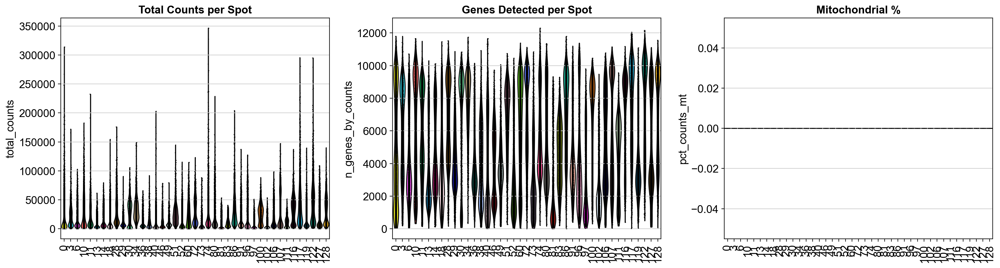

In [24]:
# QC violin plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sc.pl.violin(adata_combined, 'total_counts', groupby='sample_id', rotation=90, ax=axes[0], show=False)
axes[0].set_title('Total Counts per Spot', fontweight='bold')
axes[0].set_xlabel('')

sc.pl.violin(adata_combined, 'n_genes_by_counts', groupby='sample_id', rotation=90, ax=axes[1], show=False)
axes[1].set_title('Genes Detected per Spot', fontweight='bold')
axes[1].set_xlabel('')

sc.pl.violin(adata_combined, 'pct_counts_mt', groupby='sample_id', rotation=90, ax=axes[2], show=False)
axes[2].set_title('Mitochondrial %', fontweight='bold')
axes[2].set_xlabel('')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'qc_violin_by_sample.png'), dpi=200, bbox_inches='tight')
plt.show()

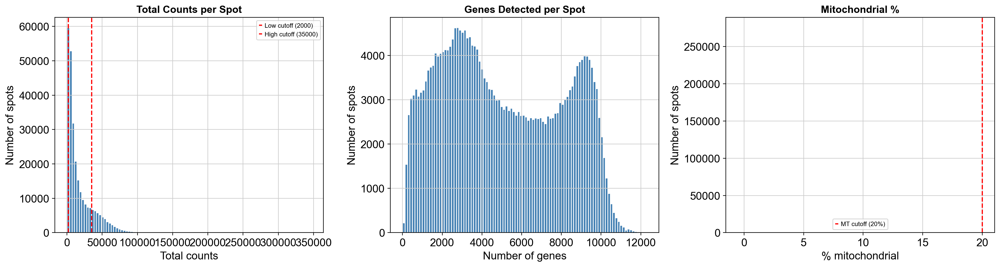

In [25]:
# QC histograms (combined across all samples)
fig, axes = plt.subplots(1, 3, figsize=(18, 5), facecolor='white')

axes[0].hist(adata_combined.obs['total_counts'], bins=100, color='steelblue', edgecolor='white')
axes[0].axvline(x=2000, color='red', linestyle='--', label='Low cutoff (2000)')
axes[0].axvline(x=35000, color='red', linestyle='--', label='High cutoff (35000)')
axes[0].set_title('Total Counts per Spot', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Total counts')
axes[0].set_ylabel('Number of spots')
axes[0].legend(fontsize=8)

axes[1].hist(adata_combined.obs['n_genes_by_counts'], bins=100, color='steelblue', edgecolor='white')
axes[1].set_title('Genes Detected per Spot', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Number of genes')
axes[1].set_ylabel('Number of spots')

axes[2].hist(adata_combined.obs['pct_counts_mt'], bins=100, color='steelblue', edgecolor='white')
axes[2].axvline(x=20, color='red', linestyle='--', label='MT cutoff (20%)')
axes[2].set_title('Mitochondrial %', fontsize=13, fontweight='bold')
axes[2].set_xlabel('% mitochondrial')
axes[2].set_ylabel('Number of spots')
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'qc_histograms.png'), dpi=200, bbox_inches='tight')
plt.show()

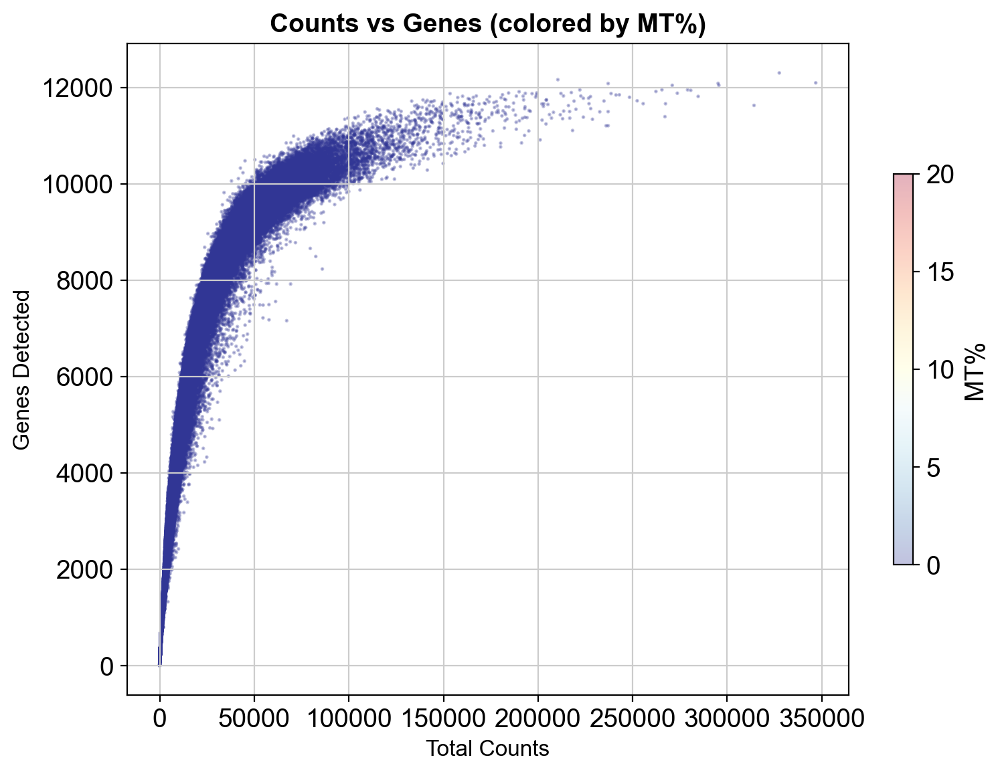

In [26]:
# Scatter: counts vs genes, colored by MT%
fig, ax = plt.subplots(figsize=(8, 6), facecolor='white')
sc_plot = ax.scatter(
    adata_combined.obs['total_counts'],
    adata_combined.obs['n_genes_by_counts'],
    c=adata_combined.obs['pct_counts_mt'],
    cmap='RdYlBu_r', s=1, alpha=0.3, vmin=0, vmax=20
)
ax.set_xlabel('Total Counts', fontsize=12)
ax.set_ylabel('Genes Detected', fontsize=12)
ax.set_title('Counts vs Genes (colored by MT%)', fontsize=14, fontweight='bold')
plt.colorbar(sc_plot, ax=ax, label='MT%', shrink=0.6)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'qc_scatter_counts_genes_mt.png'), dpi=200, bbox_inches='tight')
plt.show()

In [27]:
# Per-sample QC summary table
qc_summary = adata_combined.obs.groupby('sample_id').agg(
    n_spots=('total_counts', 'count'),
    median_counts=('total_counts', 'median'),
    median_genes=('n_genes_by_counts', 'median'),
    median_mt_pct=('pct_counts_mt', 'median'),
    mets_group=('mets_group', 'first'),
).reset_index()

qc_summary = qc_summary.sort_values('sample_id')
qc_summary.to_csv(os.path.join(OUTPUT_DIR, 'per_sample_qc_summary.csv'), index=False)
print(qc_summary.to_string(index=False))

sample_id  n_spots  median_counts  median_genes  median_mt_pct   mets_group
        0     6658         8229.0        4279.0            0.0      LN_Mets
        3     5571        16274.0        6569.0            0.0      No_Mets
        6     6414         6876.5        3207.0            0.0 Distant_Mets
       10     6138        18095.5        6658.5            0.0      No_Mets
       11     7353        12809.0        5632.0            0.0 Distant_Mets
       13     5910         3655.5        2518.5            0.0      No_Mets
       14     6855         7130.0        3726.0            0.0      No_Mets
       18     6319         4747.0        3024.0            0.0 Distant_Mets
       28     6989        20032.0        6845.0            0.0      LN_Mets
       29     6768         7038.0        3790.5            0.0 Distant_Mets
       30     6476        30508.0        8281.0            0.0      No_Mets
       34     6297        30694.0        8301.0            0.0      No_Mets
       36   

## 3. Filtering & Normalization

Filter spots and genes, then normalize and log-transform for downstream analysis.

In [28]:
print(f"Before filtering: {adata_combined.n_obs} spots, {adata_combined.n_vars} genes")

# Store raw counts
adata_combined.layers['raw_counts'] = adata_combined.X.copy()

# Filter spots
sc.pp.filter_cells(adata_combined, min_counts=2000)
sc.pp.filter_cells(adata_combined, max_counts=35000)
adata_combined = adata_combined[adata_combined.obs['pct_counts_mt'] < 20].copy()

# Filter genes
sc.pp.filter_genes(adata_combined, min_cells=10)

print(f"After filtering: {adata_combined.n_obs} spots, {adata_combined.n_vars} genes")
print(f"Spots remaining: {adata_combined.n_obs}")


# Normalize
sc.pp.normalize_total(adata_combined, target_sum=1e4)
sc.pp.log1p(adata_combined)

# Store normalized counts
adata_combined.layers['normalized'] = adata_combined.X.copy()

# Highly variable genes
sc.pp.highly_variable_genes(adata_combined, n_top_genes=3000, flavor='seurat_v3',
                             layer='raw_counts', batch_key='sample_id')
print(f"Highly variable genes: {adata_combined.var['highly_variable'].sum()}")

Before filtering: 275658 spots, 13598 genes
After filtering: 192799 spots, 13598 genes
Spots remaining: 192799
Highly variable genes: 3000


## 4. Dimensionality Reduction & Clustering

PCA on highly variable genes, batch-aware neighbor graph, UMAP, and Leiden clustering.

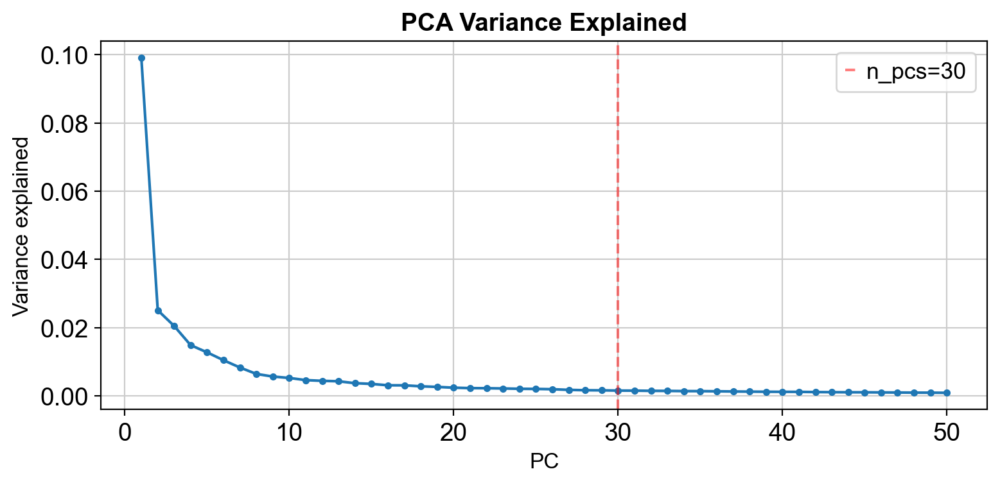

In [29]:
# PCA on HVGs
adata_combined_hvg = adata_combined[:, adata_combined.var['highly_variable']].copy()
sc.pp.scale(adata_combined_hvg, max_value=10)
sc.tl.pca(adata_combined_hvg, n_comps=50)

# Copy PCA to main object
adata_combined.obsm['X_pca'] = adata_combined_hvg.obsm['X_pca']

# Variance explained
fig, ax = plt.subplots(figsize=(8, 4), facecolor='white')
ax.plot(range(1, 51), adata_combined_hvg.uns['pca']['variance_ratio'], 'o-', markersize=3)
ax.set_xlabel('PC', fontsize=12)
ax.set_ylabel('Variance explained', fontsize=12)
ax.set_title('PCA Variance Explained', fontsize=14, fontweight='bold')
ax.axvline(x=30, color='red', linestyle='--', alpha=0.5, label='n_pcs=30')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'pca_variance.png'), dpi=200, bbox_inches='tight')
plt.show()

In [30]:
# Neighbors and UMAP
sc.pp.neighbors(adata_combined, n_neighbors=30, n_pcs=30)
sc.tl.umap(adata_combined, min_dist=0.3)

# Leiden clustering at multiple resolutions
for res in [0.3, 0.5, 0.8, 1.0]:
    sc.tl.leiden(adata_combined, resolution=res, key_added=f'leiden_{res}')
    n_clusters = adata_combined.obs[f'leiden_{res}'].nunique()
    print(f"Leiden res={res}: {n_clusters} clusters")

Leiden res=0.3: 25 clusters
Leiden res=0.5: 34 clusters
Leiden res=0.8: 44 clusters
Leiden res=1.0: 47 clusters


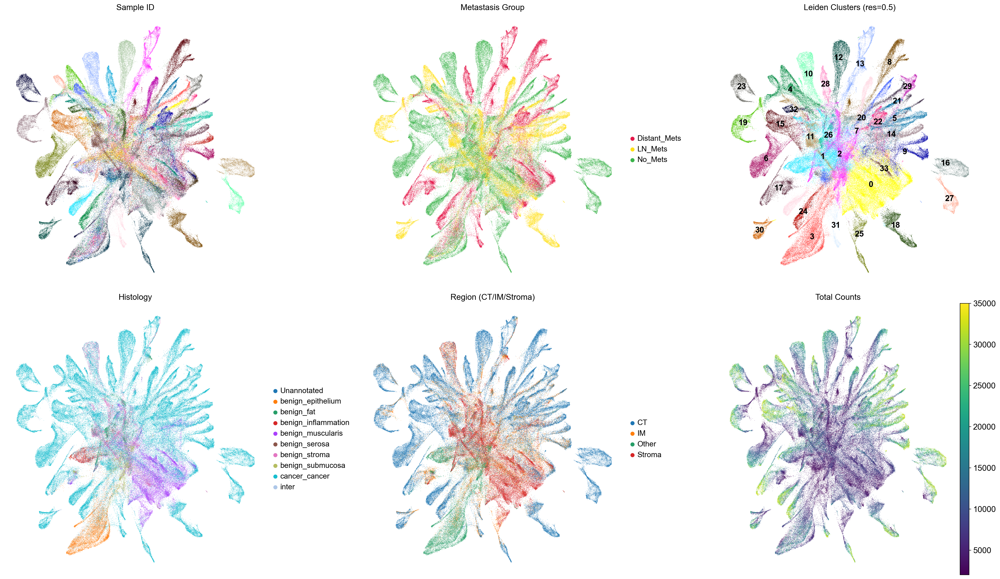

In [31]:
# UMAP colored by different metadata
fig, axes = plt.subplots(2, 3, figsize=(24, 14), facecolor='white')

sc.pl.umap(adata_combined, color='sample_id', ax=axes[0, 0], show=False, 
           title='Sample ID', legend_loc='none', size=1)

sc.pl.umap(adata_combined, color='mets_group', ax=axes[0, 1], show=False,
           title='Metastasis Group', palette={'No_Mets': '#3cb44b', 'LN_Mets': '#ffe119', 'Distant_Mets': '#e6194b'},
           size=1)

sc.pl.umap(adata_combined, color='leiden_0.5', ax=axes[0, 2], show=False,
           title='Leiden Clusters (res=0.5)', size=1, legend_loc='on data')

sc.pl.umap(adata_combined, color='histology', ax=axes[1, 0], show=False,
           title='Histology', size=1) if 'histology' in adata_combined.obs.columns else axes[1, 0].axis('off')

sc.pl.umap(adata_combined, color='region', ax=axes[1, 1], show=False,
           title='Region (CT/IM/Stroma)', size=1) if 'region' in adata_combined.obs.columns else axes[1, 1].axis('off')

sc.pl.umap(adata_combined, color='total_counts', ax=axes[1, 2], show=False,
           title='Total Counts', size=1, color_map='viridis')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'umap_overview.png'), dpi=200, bbox_inches='tight')
plt.show()

## 5. Cluster Composition Analysis

How are clusters distributed across samples, regions, and mets groups?

In [ ]:
# Cluster composition by mets group
cluster_col = 'leiden_0.5'

# Cross-tab: cluster x mets
cross = pd.crosstab(adata_combined.obs[cluster_col], adata_combined.obs['mets_group'], normalize='index') * 100

fig, ax = plt.subplots(figsize=(12, 6), facecolor='white')
cross[['No_Mets', 'LN_Mets', 'Distant_Mets']].plot(
    kind='bar', stacked=True, ax=ax,
    color=['#3cb44b', '#ffe119', '#e6194b'], edgecolor='white', linewidth=0.5
)
ax.set_ylabel('% of spots', fontsize=12)
ax.set_xlabel('Cluster', fontsize=12)
ax.set_title('Cluster Composition by Metastasis Group', fontsize=14, fontweight='bold')
ax.legend(title='Mets Group', bbox_to_anchor=(1.02, 1))
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'cluster_by_mets.png'), dpi=200, bbox_inches='tight')
plt.show()

# Cluster x Region
if 'region' in adata_combined.obs.columns and adata_combined.obs['region'].nunique() > 1:
    cross_reg = pd.crosstab(adata_combined.obs[cluster_col], adata_combined.obs['region'], normalize='index') * 100
    col_order = [c for c in ['CT', 'IM', 'Stroma', 'Other', 'NA'] if c in cross_reg.columns]
    
    fig, ax = plt.subplots(figsize=(12, 6), facecolor='white')
    cross_reg[col_order].plot(
        kind='bar', stacked=True, ax=ax,
        color=['#E64B35', '#F39B7F', '#4DBBD5', '#CCCCCC', '#EEEEEE'][:len(col_order)],
        edgecolor='white', linewidth=0.5
    )
    ax.set_ylabel('% of spots', fontsize=12)
    ax.set_xlabel('Cluster', fontsize=12)
    ax.set_title('Cluster Composition by Region', fontsize=14, fontweight='bold')
    ax.legend(title='Region', bbox_to_anchor=(1.02, 1))
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'cluster_by_region.png'), dpi=200, bbox_inches='tight')
    plt.show()

## 6. Spatial Cluster Maps

Plot Leiden clusters on H&E for representative samples (38=No Mets, 107=LN Mets, 80=Distant Mets).

In [ ]:
EXAMPLE_SAMPLES = {'No_Mets': '38', 'LN_Mets': '107', 'Distant_Mets': '80'}
cluster_col = 'leiden_0.5'

# Get cluster colors from the combined UMAP
cluster_colors = dict(zip(
    adata_combined.obs[cluster_col].cat.categories,
    adata_combined.uns.get(f'{cluster_col}_colors',
                           plt.cm.tab20.colors[:adata_combined.obs[cluster_col].nunique()])
))

for mets_label, sid in EXAMPLE_SAMPLES.items():
    # Get spots for this sample from the combined object
    mask = adata_combined.obs['sample_id'] == sid
    if mask.sum() == 0:
        # Try from the index labels
        mask = adata_combined.obs.index.str.startswith(sid + '-') | (adata_combined.obs['sample_id'] == sid)
    
    if mask.sum() == 0:
        print(f"  {sid}: no spots found in combined object, skipping")
        continue

    # Load original h5ad for H&E image
    adata_orig = sc.read_h5ad(os.path.join(SAMPLE_DIR, f"{sid}.h5ad"))
    
    lib_id = list(adata_orig.uns['spatial'].keys())[0]
    img = adata_orig.uns['spatial'][lib_id]['images']['hires']
    sf = adata_orig.uns['spatial'][lib_id]['scalefactors']['tissue_hires_scalef']
    coords = adata_orig.obsm['spatial']
    
    # Crop
    x_img = coords[:, 0] * sf
    y_img = coords[:, 1] * sf
    pad = 500 * sf
    y0 = max(0, int(coords[:, 1].min() * sf - pad))
    y1 = min(img.shape[0], int(coords[:, 1].max() * sf + pad))
    x0 = max(0, int(coords[:, 0].min() * sf - pad))
    x1 = min(img.shape[1], int(coords[:, 0].max() * sf + pad))
    img_cr = img[y0:y1, x0:x1]
    x_cr = x_img - x0
    y_cr = y_img - y0

    # Get cluster assignments for this sample
    sample_obs = adata_combined.obs[mask]
    clusters = sample_obs[cluster_col].values

    # Note: spot count may differ if filtering removed spots
    # Map by barcode index
    n_orig = len(adata_orig)
    n_filtered = len(sample_obs)
    
    fig, axes = plt.subplots(1, 3, figsize=(24, 8), facecolor='white')

    # Panel 1: H&E
    axes[0].imshow(img_cr)
    axes[0].set_title('H&E', fontsize=13, fontweight='bold')
    axes[0].axis('off')

    # Panel 2: Histology on H&E
    if 'histology' in adata_orig.obs.columns:
        hist = adata_orig.obs['histology'].values
        hist_colors = {
            'cancer_cancer': '#E64B35', 'benign_stroma': '#4DBBD5',
            'benign_fat': '#F9E076', 'inter': '#91D1C2', 'stroma': '#8491B4',
            'benign_muscularis': '#B09C85',
        }
        axes[1].imshow(img_cr, alpha=0.3)
        for h_label in np.unique(hist):
            hmask = hist == h_label
            color = hist_colors.get(h_label, '#999999')
            axes[1].scatter(x_cr[hmask], y_cr[hmask], c=color, s=3, edgecolors='none', alpha=0.7, label=h_label)
        axes[1].set_title('Histology', fontsize=13, fontweight='bold')
        axes[1].axis('off')
        axes[1].legend(fontsize=6, markerscale=2, loc='upper left', framealpha=0.8)
    else:
        axes[1].axis('off')

    # Panel 3: Leiden clusters on H&E
    # If spot counts match, map directly; otherwise plot what we have
    axes[2].imshow(img_cr, alpha=0.3)
    if n_filtered == n_orig:
        for cl in np.unique(clusters):
            cl_mask = clusters == cl
            color = cluster_colors.get(cl, '#999999')
            axes[2].scatter(x_cr[cl_mask], y_cr[cl_mask], c=[color], s=3,
                           edgecolors='none', alpha=0.7, label=f'C{cl}')
    else:
        # Filtered - just note the mismatch
        axes[2].text(0.5, 0.5, f'Spots filtered: {n_orig} -> {n_filtered}',
                    transform=axes[2].transAxes, ha='center', fontsize=12)
    axes[2].set_title(f'Leiden Clusters (res=0.5)', fontsize=13, fontweight='bold')
    axes[2].axis('off')
    axes[2].legend(fontsize=5, markerscale=2, loc='upper left', framealpha=0.8, ncol=2)

    plt.suptitle(f'Sample {sid} - {mets_label.replace("_", " ")}',
                 fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f'spatial_clusters_{sid}_{mets_label}.png'),
                dpi=200, bbox_inches='tight')
    plt.show()
    print(f"  {sid} done ({n_filtered} spots after filtering)")

## 7. Save Combined Object

In [ ]:
# Save the combined, processed AnnData
save_path = os.path.join(OUTPUT_DIR, 'adata_combined_clustered.h5ad')
adata_combined.write_h5ad(save_path)
print(f"Saved combined object: {save_path}")
print(f"  {adata_combined.n_obs} spots, {adata_combined.n_vars} genes")
print(f"  Clusters: {adata_combined.obs['leiden_0.5'].nunique()} (res=0.5)")
print("Done!")

In [ ]:
import scanpy as sc
adata = sc.read_h5ad("/Users/adiallo/Desktop/Thesis/Data_Documents/All_Data/Visium_samples/Visium_Data/samples/127.h5ad")

# Check for any mitochondrial gene naming patterns
mt_patterns = [g for g in adata.var_names if any(p in g.upper() for p in ['MT-', 'MT.', 'MITO'])]
print("MT-like genes:", mt_patterns[:20])

# Also check if they were filtered
print("\nTotal genes:", adata.n_vars)
print("Gene name examples:", list(adata.var_names[:10]))

In [19]:
import scanpy as sc
import numpy as np

adata = sc.read_h5ad("/Users/adiallo/Desktop/Thesis/Data_Documents/All_Data/Visium_samples/Visium_Data/samples/127.h5ad")

print("=== DATA STRUCTURE ===")
print(f"Spots: {adata.n_obs}")
print(f"Genes: {adata.n_vars}")
print()

# Check if counts are raw integers or normalized
X = adata.X.toarray() if hasattr(adata.X, 'toarray') else adata.X
print("=== COUNT MATRIX ===")
print(f"Min value: {X.min()}")
print(f"Max value: {X.max()}")
print(f"Has decimals: {not np.allclose(X, np.round(X))}")
print(f"Dtype: {X.dtype}")
print()

# Check for filtered spots (in_tissue)
print("=== SPOT FILTERING ===")
if 'in_tissue' in adata.obs.columns:
    print(f"in_tissue values: {adata.obs['in_tissue'].value_counts().to_dict()}")
print()

# Check var (gene) metadata
print("=== GENE METADATA ===")
print(f"var columns: {list(adata.var.columns)}")
if len(adata.var.columns) > 0:
    print(adata.var.head())
print()

# Check for common filtered gene patterns
print("=== GENE FILTERING CHECKS ===")
ribo = [g for g in adata.var_names if g.startswith(('RPS', 'RPL'))]
print(f"Ribosomal genes present: {len(ribo)}")
hb = [g for g in adata.var_names if g.startswith('HB') and not g.startswith('HBS')]
print(f"Hemoglobin genes present: {len(hb)} — {hb}")
mt = [g for g in adata.var_names if g.startswith('MT-')]
print(f"MT genes present: {len(mt)}")
print()

# Check for stored preprocessing info
print("=== UNS (processing metadata) ===")
for k in adata.uns.keys():
    print(f"  {k}: {type(adata.uns[k])}")
print()

# Check layers
print("=== LAYERS ===")
print(f"Layers: {list(adata.layers.keys())}")
print()

# Check obsm
print("=== OBSM ===")
print(f"obsm keys: {list(adata.obsm.keys())}")

=== DATA STRUCTURE ===
Spots: 7173
Genes: 13598

=== COUNT MATRIX ===
Min value: 0.0
Max value: 15895.0
Has decimals: False
Dtype: float32

=== SPOT FILTERING ===
in_tissue values: {'1': 7173}

=== GENE METADATA ===
var columns: ['gene_ids', 'feature_types', 'genome']
                gene_ids    feature_types  genome
SAMD11   ENSG00000187634  Gene Expression  GRCh38
NOC2L    ENSG00000188976  Gene Expression  GRCh38
KLHL17   ENSG00000187961  Gene Expression  GRCh38
PLEKHN1  ENSG00000187583  Gene Expression  GRCh38
HES4     ENSG00000188290  Gene Expression  GRCh38

=== GENE FILTERING CHECKS ===
Ribosomal genes present: 0
Hemoglobin genes present: 5 — ['HBEGF', 'HBP1', 'HBB', 'HBD', 'HBA2']
MT genes present: 0

=== UNS (processing metadata) ===
  _scvi_manager_uuid: <class 'str'>
  _scvi_uuid: <class 'str'>
  histology_colors: <class 'numpy.ndarray'>
  mod: <class 'dict'>
  spatial: <class 'dict'>

=== LAYERS ===
Layers: []

=== OBSM ===
obsm keys: ['means_cell_abundance_w_sf', 'q05_cell_

In [20]:
import scanpy as sc
import numpy as np
import os

sample_dir = "/Users/adiallo/Desktop/Thesis/Data_Documents/All_Data/Visium_samples/Visium_Data/samples"

all_counts = []
all_genes = []

for f in sorted(os.listdir(sample_dir)):
    if not f.endswith('.h5ad'):
        continue
    adata = sc.read_h5ad(os.path.join(sample_dir, f))
    X = adata.X.toarray() if hasattr(adata.X, 'toarray') else adata.X
    all_counts.extend(X.sum(axis=1).tolist())
    all_genes.extend((X > 0).sum(axis=1).tolist())

all_counts = np.array(all_counts)
all_genes = np.array(all_genes)

print(f"Total spots across 41 samples: {len(all_counts)}")
print(f"\nTotal counts per spot: min={all_counts.min():.0f}, median={np.median(all_counts):.0f}, max={all_counts.max():.0f}")
print(f"Genes detected per spot: min={all_genes.min():.0f}, median={np.median(all_genes):.0f}, max={all_genes.max():.0f}")

Total spots across 41 samples: 719757

Total counts per spot: min=2, median=5802, max=583596
Genes detected per spot: min=2, median=2097, max=13455


In [32]:
adata = sc.read_h5ad(os.path.join(SAMPLE_DIR, "0.h5ad"))

print("=== .obs columns ===")
print(adata.obs.columns.tolist())
print()

print("=== .obsm keys ===")
print(list(adata.obsm.keys()))
print()

print("=== .uns keys ===")
print(list(adata.uns.keys()))
print()

# Check any columns that look like region annotations
for col in adata.obs.columns:
    if adata.obs[col].dtype == "object" or adata.obs[col].dtype.name == "category":
        print(f"\n--- {col} ---")
        print(adata.obs[col].value_counts())

=== .obs columns ===
['in_tissue', 'array_row', 'array_col', '_indices', '_scvi_batch', '_scvi_labels', 'histology', 'region', 'refined_region', 'stromal_ratio', 'immune_score', 'cd8_score', 'immune_hot_cold', 'tls_score', 'tls_spot', 'tumor_budding', 'hypoxia_score', 'pni_spot', 'schwann_score', 'lvi_spot', 'endo_score', 'lymphatic_score']

=== .obsm keys ===
['means_cell_abundance_w_sf', 'q05_cell_abundance_w_sf', 'q95_cell_abundance_w_sf', 'spatial', 'stds_cell_abundance_w_sf']

=== .uns keys ===
['_scvi_manager_uuid', '_scvi_uuid', 'histology_colors', 'mod', 'spatial']


--- in_tissue ---
in_tissue
1    6658
Name: count, dtype: int64

--- array_row ---
array_row
76    107
94    106
92    106
86    106
78    106
     ... 
65     86
64     80
63     68
62     52
61      6
Name: count, Length: 67, dtype: int64

--- array_col ---
array_col
31     34
5      34
1      34
7      34
33     34
       ..
208    17
209    14
210    10
211     3
212     1
Name: count, Length: 213, dtype: int64